In [ ]:
import sys
sys.path.append(r'D:\NUMN32\Adri')
import objects
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Solve Lotka-Volterra IVP with parameters (3,9,15,15) and RK34


In [2]:
a,b,c,d = 3,9,15,15
y0 = np.array([1,1])
t0 = 0
T = 10
N = 100

def H(x,y):
    return c*x+b*y-d*np.log(x)-a*np.log(y)

In [3]:
LotkaVol = objects.LoktaVolterra(t0=t0,y0=y0,T=T,a=a,b=b,c=c,d=d)

In [4]:
solver = objects.RK34(ivp=LotkaVol,N=N,tol=1e-7,adaptative=True)

In [5]:
solver.integrate()

In [6]:
t, prey, pred = solver.grid, solver.u[:,0], solver.u[:,1]

In [7]:
solver.N

1365

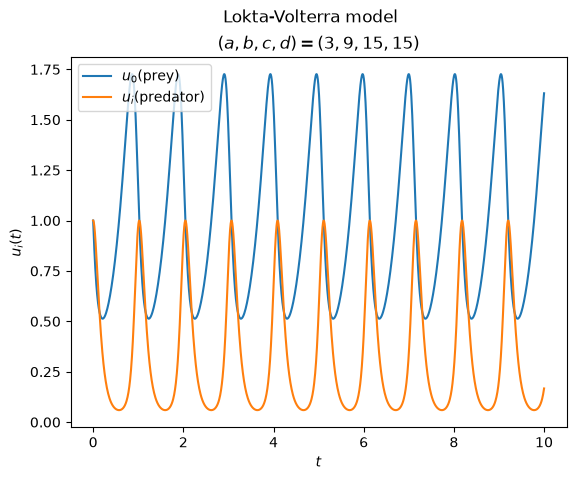

In [8]:
plt.plot(t,prey,label=rf"$u_0$(prey)")
plt.plot(t,pred,label=rf"$u_i$(predator)")
plt.suptitle("Lokta-Volterra model")
plt.title(rf"$(a,b,c,d) = (3,9,15,15)$")
plt.xlabel(rf"$t$")
plt.ylabel(rf"$u_i(t)$")
plt.legend()

In [9]:
est_prey_period = np.mean(np.diff([t[x] for x in signal.find_peaks(prey)[0]]))
est_pred_period = np.mean(np.diff([t[x] for x in signal.find_peaks(pred)[0]]))

In [10]:
est_prey_period, est_pred_period

(np.float64(1.0221223668888446), np.float64(1.0227323326839948))

Text(0, 0.5, 'predator')

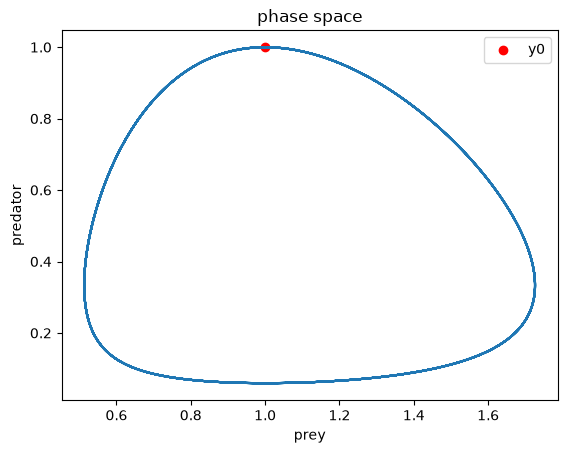

In [11]:
plt.scatter(y0[0],y0[1],color="red",label="y0")
plt.plot(prey,pred)
plt.legend()
plt.title("phase space")
plt.xlabel("prey")
plt.ylabel("predator")

In [12]:
invar = np.array([H(prey[i],pred[i]) for i,_ in enumerate(t)])
invar_deviation = np.abs( invar/H(y0[0],y0[1]) - 1)


Text(0.5, 1.0, '$|\\frac{H(x,y)}{H(x(0),y(0))} - 1|$')

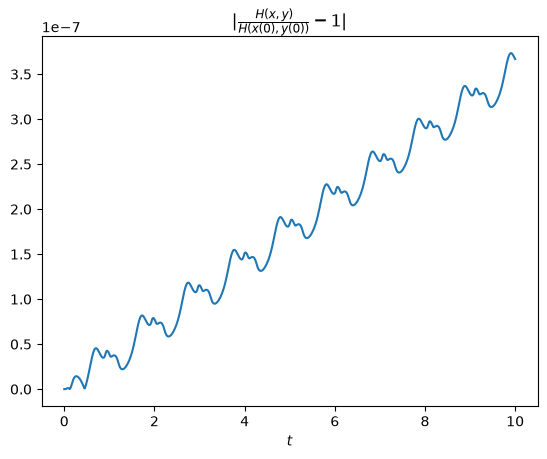

In [13]:
plt.plot(t, invar_deviation )
plt.xlabel(r"$t$")
plt.title(r"$|\frac{H(x,y)}{H(x(0),y(0))} - 1|$")

In [14]:
invar_deviation_flat = np.abs((invar_deviation[1:]-invar_deviation[0])/t[1:])

Text(0.5, 1.0, 'H(x,y) "deviation" slope amplitude')

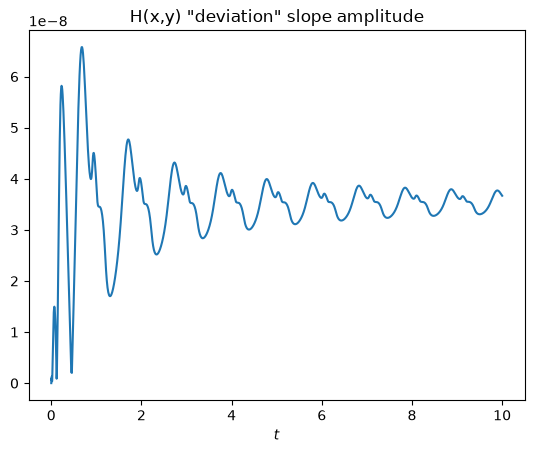

In [15]:
plt.plot(t[1:],invar_deviation_flat)
plt.xlabel(rf"$t$")
plt.title("H(x,y) \"deviation\" slope amplitude")

In [16]:
est_invar_period = np.mean(np.diff([t[x] for x in signal.find_peaks(invar_deviation_flat)[0]]))


In [17]:
est_pred_period

np.float64(1.0227323326839948)